<a href="https://colab.research.google.com/github/SAHIBA-09/summit-syndicate-mcx-gold/blob/main/Another_copy_of_mcx_gold_colab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MCX Gold: cross-contract relative value (Summit Syndicate)
Run the cells top to bottom (Runtime > Run all). In cell 1, select all your Bhavcopy CSV files at once.

In [ ]:
import os
os.makedirs("data", exist_ok=True)
try:
    from google.colab import files
    up = files.upload()                      # choose all Bhavcopy CSVs
    for name, content in up.items():
        open(f"data/{name}", "wb").write(content)
except ImportError:
    print("Not on Colab: put CSVs in ./data")

Saving BhavCopyDateWise_01102026.csv to BhavCopyDateWise_01102026.csv
Saving BhavCopyDateWise_02102026.csv to BhavCopyDateWise_02102026.csv
Saving BhavCopyDateWise_03102026.csv to BhavCopyDateWise_03102026.csv
Saving BhavCopyDateWise_04102026.csv to BhavCopyDateWise_04102026.csv
Saving BhavCopyDateWise_05102026.csv to BhavCopyDateWise_05102026.csv
Saving BhavCopyDateWise_06102026.csv to BhavCopyDateWise_06102026.csv
Saving BhavCopyDateWise_07102026.csv to BhavCopyDateWise_07102026.csv
Saving BhavCopyDateWise_08102026.csv to BhavCopyDateWise_08102026.csv
Saving BhavCopyDateWise_09102026.csv to BhavCopyDateWise_09102026.csv
Saving BhavCopyDateWise_10102026.csv to BhavCopyDateWise_10102026.csv
Saving BhavCopyDateWise_11102026.csv to BhavCopyDateWise_11102026.csv
Saving BhavCopyDateWise_12102026.csv to BhavCopyDateWise_12102026.csv
Saving BhavCopyDateWise_13102026.csv to BhavCopyDateWise_13102026.csv
Saving BhavCopyDateWise_14102026.csv to BhavCopyDateWise_14102026.csv
Saving BhavCopyDateW

Days in data: 3 | pair-expiry series tested: 36 | trades: 0
Gross P&L: 0.00 Rs/g | Costs at 2.0 bps: 0.00 | NET: 0.00 Rs/g (per 1 g of each leg)

Net P&L at different cost levels (Rs/g):
0 bps     0.0
1 bps     0.0
2 bps     0.0
5 bps     0.0
10 bps    0.0



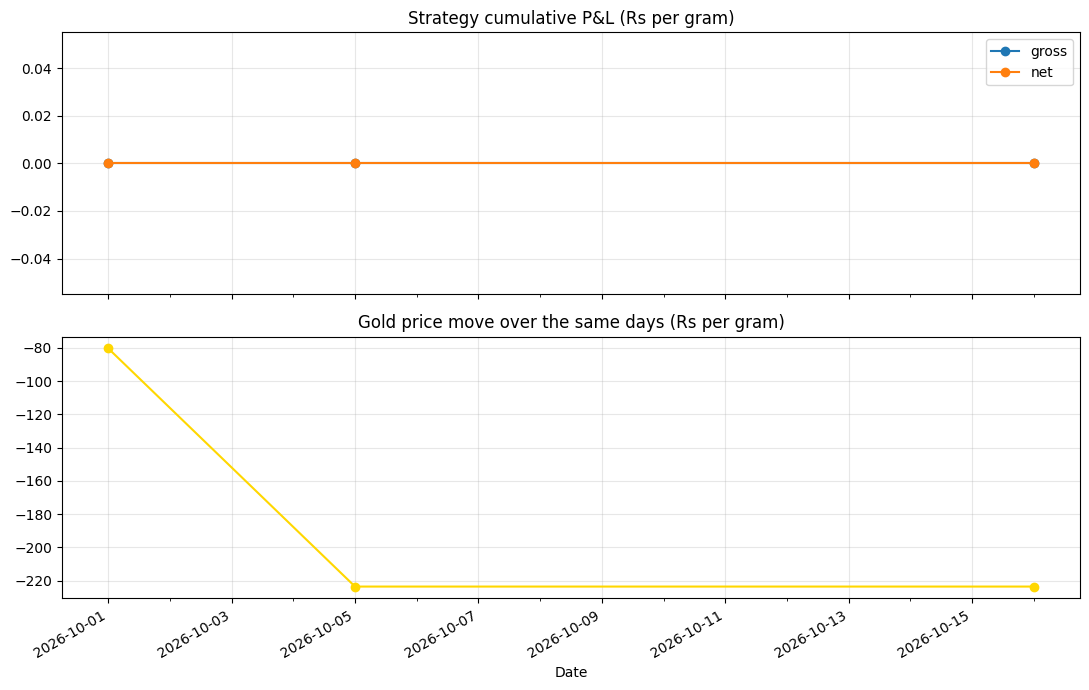

,Date,pair,exp_month,pos,z,spread


In [ ]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- BACKTEST SETTINGS (change these; cost numbers should come from Anjali's verified sources) ----
K = 2.0               # enter when |z| > K
EXIT_Z = 0.5          # exit when |z| < EXIT_Z
MIN_OBS = 5           # past days needed before a band exists
NO_ENTRY_DAYS = 5     # stay flat this many days before expiry (tender-period buffer, ASSUMPTION: set from MCX calendar)
MIN_VOL = 1           # minimum volume on each leg to trade
COST_BPS = 2.0        # all-in cost per leg per side (brokerage + charges + slippage), in basis points. PLACEHOLDER

def backtest_pair(df, a, b):
    A = df[df["Symbol"] == a].drop_duplicates(["Date", "exp_month"]).set_index(["Date", "exp_month"])
    B = df[df["Symbol"] == b].drop_duplicates(["Date", "exp_month"]).set_index(["Date", "exp_month"])
    idx = A.index.intersection(B.index)
    if len(idx) == 0: return pd.DataFrame()
    d = pd.DataFrame({"pa": A.loc[idx, "rs_per_g"], "pb": B.loc[idx, "rs_per_g"], "va": A.loc[idx, "Volume"],
                      "vb": B.loc[idx, "Volume"], "ea": A.loc[idx, "ExpiryDate"], "eb": B.loc[idx, "ExpiryDate"]}).reset_index()
    out = []
    for m, g in d.groupby("exp_month"):
        g = g.sort_values("Date").reset_index(drop=True)
        g["spread"] = g["pa"] - g["pb"]
        past = g["spread"].shift(1)                                    # band uses PAST days only
        g["z"] = (g["spread"] - past.expanding(MIN_OBS).mean()) / past.expanding(MIN_OBS).std()
        left = (g[["ea", "eb"]].min(axis=1) - g["Date"]).dt.days
        liquid = (g["va"] >= MIN_VOL) & (g["vb"] >= MIN_VOL)
        pos, poss = 0, []
        for z, dl, lq in zip(g["z"], left, liquid):
            if pos != 0 and (dl <= NO_ENTRY_DAYS or (pd.notna(z) and abs(z) < EXIT_Z)): pos = 0   # exit
            elif pos == 0 and lq and dl > NO_ENTRY_DAYS and pd.notna(z):                          # entry
                pos = -1 if z > K else (1 if z < -K else 0)
            poss.append(pos)
        poss[-1] = 0                                                   # nothing to trade on after the last day
        g["pos"] = poss
        g["gross"] = (g["pos"] * (g["spread"].shift(-1) - g["spread"])).fillna(0)   # decided at close t, earns t -> t+1
        prev = g["pos"].shift(1).fillna(0)
        g["dpos"] = (g["pos"] - prev).abs()
        g["entry"] = ((g["pos"] != 0) & (prev == 0)).astype(int)
        g["notional"] = g["pa"] + g["pb"]
        g["gold"] = (((g["pa"] + g["pb"]) / 2).shift(-1) - (g["pa"] + g["pb"]) / 2).fillna(0)
        g["pair"] = f"{a}-{b}"
        out.append(g)
    return pd.concat(out)

pairs = list(itertools.combinations(QUOTE_BASE_G, 2))
res = pd.concat([backtest_pair(df, a, b) for a, b in pairs], ignore_index=True)
res["cost"] = res["dpos"] * res["notional"] * COST_BPS / 1e4
res["net"] = res["gross"] - res["cost"]

n_tr = int(res["entry"].sum())
print(f"Days in data: {df['Date'].nunique()} | pair-expiry series tested: {res.groupby(['pair','exp_month']).ngroups} | trades: {n_tr}")
print(f"Gross P&L: {res['gross'].sum():.2f} Rs/g | Costs at {COST_BPS} bps: {res['cost'].sum():.2f} | NET: {res['net'].sum():.2f} Rs/g (per 1 g of each leg)")
turn = (res["dpos"] * res["notional"]).sum()
if turn > 0: print(f"Break-even all-in cost: {res['gross'].sum() / turn * 1e4:.2f} bps per leg per side")
print("\nNet P&L at different cost levels (Rs/g):")
print(pd.Series({f"{b} bps": res["gross"].sum() - (res["dpos"] * res["notional"]).sum() * b / 1e4 for b in [0, 1, 2, 5, 10]}).round(2).to_string())
if n_tr < 30: print(f"\nWARNING: only {n_tr} trades. Too few to draw conclusions: report as a preliminary result.")

daily = res.groupby("Date")[["gross", "net", "gold"]].sum()
daily["gold"] = res.groupby("Date")["gold"].mean()
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
daily[["gross", "net"]].cumsum().plot(ax=ax[0], marker="o"); ax[0].set_title("Strategy cumulative P&L (Rs per gram)"); ax[0].grid(alpha=.3)
daily["gold"].cumsum().plot(ax=ax[1], marker="o", color="gold"); ax[1].set_title("Gold price move over the same days (Rs per gram)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
if daily["net"].std() > 0 and daily["gold"].std() > 0:
    print(f"Correlation of strategy daily P&L with gold move: {daily['net'].corr(daily['gold']):.2f}")
trades = res[res["entry"] == 1][["Date", "pair", "exp_month", "pos", "z", "spread"]]
trades

In [ ]:
import glob, re
import pandas as pd
import matplotlib.pyplot as plt

# ---- CONFIG: verify against the MCX gold contract specs page ----
QUOTE_BASE_G = {"GOLDM": 10, "GOLDTEN": 10, "GOLDGUINEA": 8, "GOLDPETAL": 1}   # grams the quoted price refers to
PURITY = {"GOLDM": 995, "GOLDTEN": 999, "GOLDGUINEA": 999, "GOLDPETAL": 999}
BASIS = 995

def _key(c):
    return re.sub(r"[^a-z0-9]", "", str(c).lower())

def _read(f):
    d = pd.read_csv(f)
    d.columns = [str(c).strip() for c in d.columns]
    ren = {}
    for c in d.columns:
        k = _key(c)
        if k in ("expirydate", "expiry", "expdate") and "ExpiryDate" not in ren.values(): ren[c] = "ExpiryDate"
        elif (k.startswith("openinterest") or k == "oi") and "OpenInterest" not in ren.values(): ren[c] = "OpenInterest"
        elif k.startswith("volume") and "Volume" not in ren.values(): ren[c] = "Volume"   # e.g. Volume(In Lots)
        elif k in ("date", "tradedate") and "Date" not in ren.values(): ren[c] = "Date"
        elif k in ("symbol", "commodity") and "Symbol" not in ren.values(): ren[c] = "Symbol"
        elif k in ("open", "high", "low", "close") and k.capitalize() not in ren.values(): ren[c] = k.capitalize()
    return d.rename(columns=ren)

def _dates(s, first_fmt):
    s = s.astype(str).str.strip()
    out = pd.to_datetime(s, format=first_fmt, errors="coerce")
    rest = out.isna()
    if rest.any():
        out[rest] = pd.to_datetime(s[rest], format="mixed", dayfirst=True, errors="coerce")
    return out

def load(folder="data"):
    files = glob.glob(f"{folder}/*.csv")
    assert files, "No CSV files in data/"
    parts = [_read(f) for f in files]
    df = pd.concat(parts, ignore_index=True)
    need = ["Symbol", "Date", "ExpiryDate", "Close", "Volume", "OpenInterest"]
    miss = [c for c in need if c not in df.columns]
    assert not miss, f"Missing columns {miss}. Columns found: {df.columns.tolist()}"
    if "Instrument Name" in df.columns:                                   # keep futures, drop options
        df = df[df["Instrument Name"].astype(str).str.upper().str.startswith("FUT")]
    df["Symbol"] = df["Symbol"].astype(str).str.strip().str.upper()      # symbols can be space-padded
    df = df[df["Symbol"].isin(QUOTE_BASE_G)].copy()
    df["Date"] = _dates(df["Date"], "%m/%d/%Y")
    df["ExpiryDate"] = _dates(df["ExpiryDate"], "%d%b%Y")
    for col in ["Open", "High", "Low", "Close", "Volume", "OpenInterest"]:
        if col in df.columns: df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["Date", "ExpiryDate", "Close"])
    df = df[df["Date"] <= df["ExpiryDate"]]
    return df.drop_duplicates(["Date", "Symbol", "ExpiryDate"]).sort_values(["Date", "Symbol"])

def normalize(df):
    df = df.copy()
    df["rs_per_g"] = df["Close"] / df["Symbol"].map(QUOTE_BASE_G) * BASIS / df["Symbol"].map(PURITY)
    df["contract"] = df["Symbol"] + " " + df["ExpiryDate"].dt.strftime("%b%Y")
    df["exp_month"] = df["ExpiryDate"].dt.to_period("M")
    return df

def spread(df, a, b, min_obs=3, k=2.0):
    x = df[df["Symbol"] == a].set_index(["Date", "exp_month"])["rs_per_g"]
    y = df[df["Symbol"] == b].set_index(["Date", "exp_month"])["rs_per_g"]
    s = (x - y).dropna().rename("spread").reset_index().sort_values("Date")
    out = []
    for m, g in s.groupby("exp_month"):
        g = g.copy(); past = g["spread"].shift(1)                  # band uses PAST days only: no look-ahead
        g["mean"] = past.expanding(min_obs).mean(); g["std"] = past.expanding(min_obs).std()
        g["z"] = (g["spread"] - g["mean"]) / g["std"]; g["flag"] = g["z"].abs() > k
        out.append(g)
    return pd.concat(out) if out else s

df = normalize(load("data"))
print(f"{df['Date'].min().date()} to {df['Date'].max().date()} | {df['Date'].nunique()} trading days | {df['contract'].nunique()} contracts")

2026-10-01 to 2026-10-16 | 3 trading days | 25 contracts


## Table for the Market slide: volume and open interest from real data

In [ ]:
last = df["Date"].max()
tbl = df.groupby("Symbol").agg(avg_daily_volume=("Volume", "mean"), total_volume=("Volume", "sum")).round(0)
tbl["open_interest_last_day"] = df[df["Date"] == last].groupby("Symbol")["OpenInterest"].sum()
tbl

,avg_daily_volume,total_volume,open_interest_last_day
Symbol,,,
GOLDGUINEA,2255.0,40590,29340
GOLDM,8691.0,156439,76105
GOLDPETAL,49666.0,893987,473164
GOLDTEN,5709.0,102762,61446


## Chart 1: all contracts on one basis (Rs per gram, 995 purity)

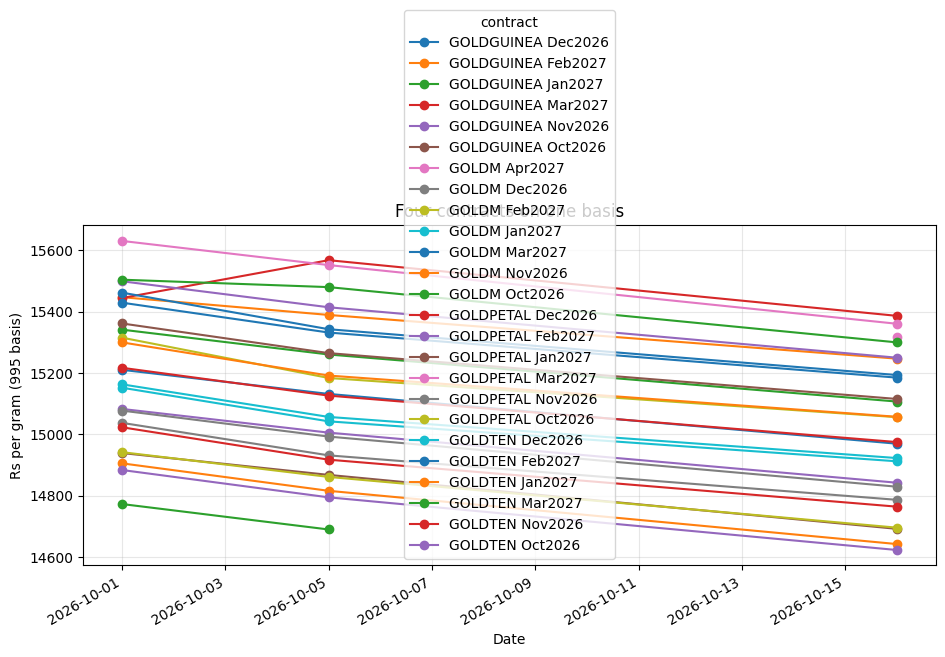

In [ ]:
wide = df.pivot_table(index="Date", columns="contract", values="rs_per_g")
ax = wide.plot(figsize=(11, 5), marker="o"); ax.set_ylabel("Rs per gram (995 basis)"); ax.set_title("Four contracts on one basis"); plt.grid(alpha=.3); plt.show()

## Chart 2: spread vs its normal range (change A, B, K)

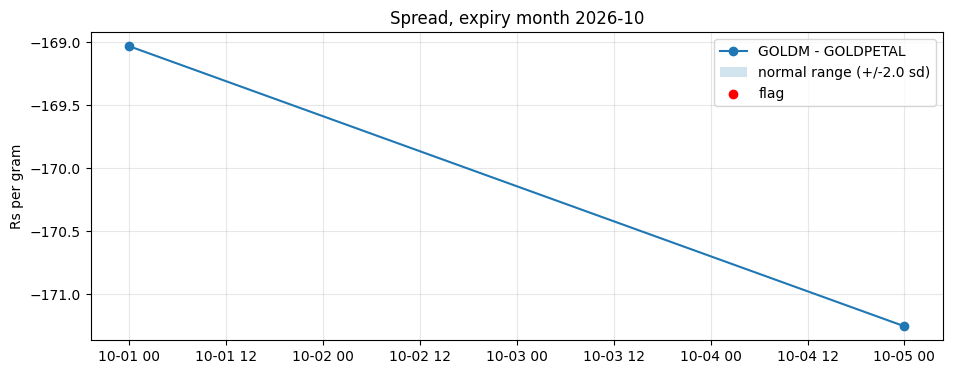

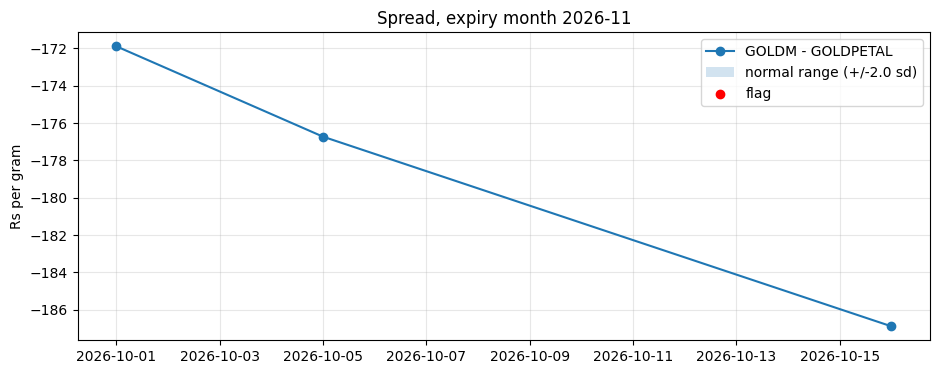

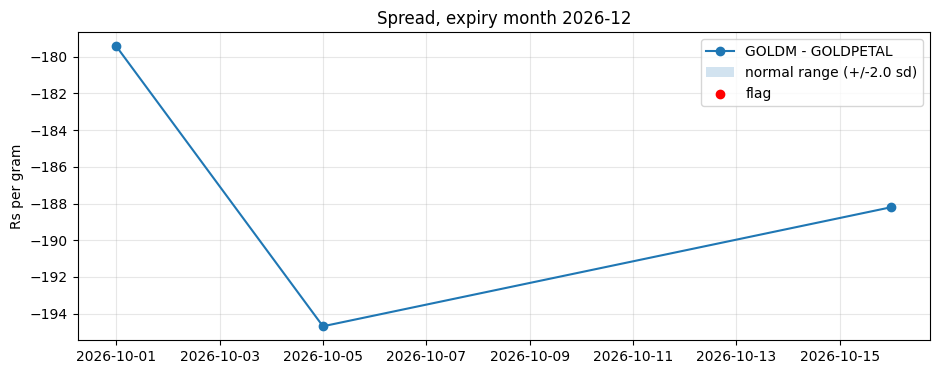

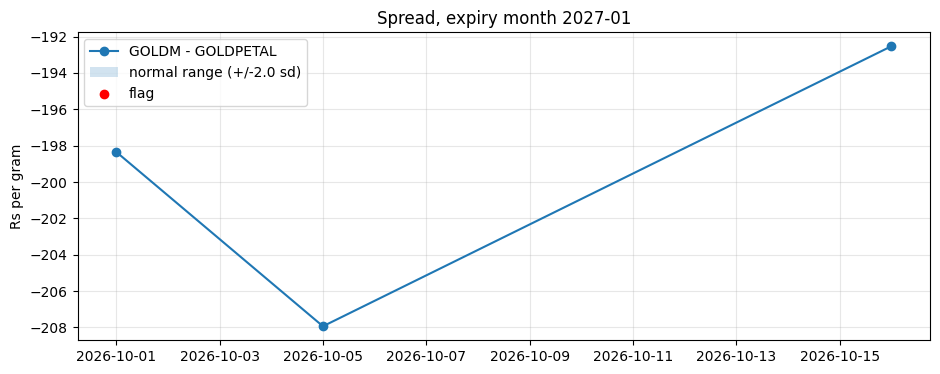

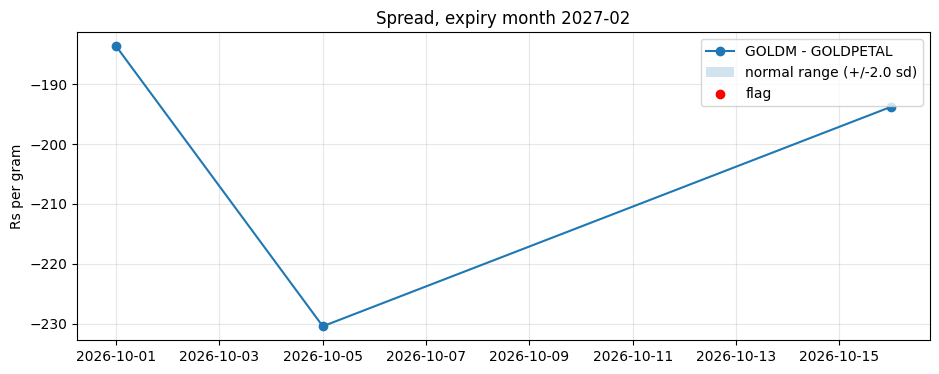

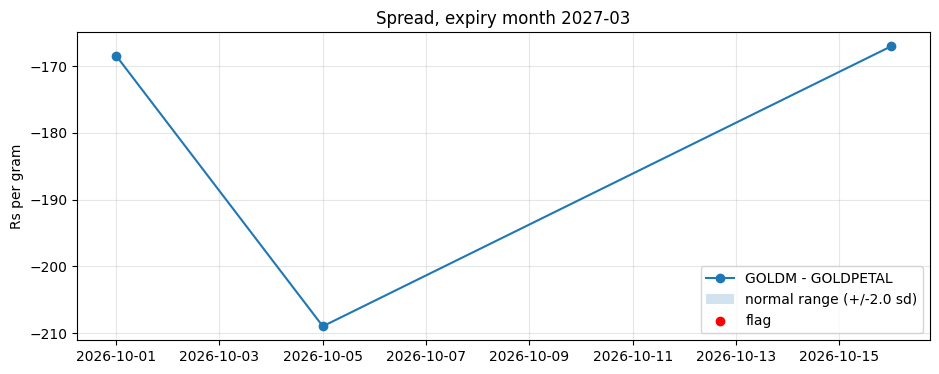

QUIET: no meaningful signal. (No edge is a valid result.)
Costs and slippage are NOT applied: a flag is a candidate, not a trade.


In [ ]:
A, B, K = "GOLDM", "GOLDPETAL", 2.0
sp = spread(df, A, B, k=K)
if sp.empty:
    print("No same-expiry-month overlap between these two contracts in your data.")
else:
    for m, g in sp.groupby("exp_month"):
        fig, ax = plt.subplots(figsize=(11, 4))
        ax.plot(g["Date"], g["spread"], marker="o", label=f"{A} - {B}")
        ax.fill_between(g["Date"], g["mean"] - K*g["std"], g["mean"] + K*g["std"], alpha=.2, label=f"normal range (+/-{K} sd)")
        ax.scatter(g[g["flag"]]["Date"], g[g["flag"]]["spread"], color="red", zorder=5, label="flag")
        ax.set_title(f"Spread, expiry month {m}"); ax.set_ylabel("Rs per gram"); ax.legend(); ax.grid(alpha=.3); plt.show()
    hits = sp[sp["flag"]]
    print("QUIET: no meaningful signal. (No edge is a valid result.)" if hits.empty else f"{len(hits)} day(s) outside the normal range:")
    if not hits.empty: display(hits[["Date", "exp_month", "spread", "z"]])
print("Costs and slippage are NOT applied: a flag is a candidate, not a trade.")